In [1]:
# %%
# ==============================================================================
# CELL 1: DATA LOADING, LABEL EXTRACTION & PATIENT-LEVEL STRATIFICATION
# ==============================================================================
!pip install medspacy
import os
import re
import ast
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
from collections import defaultdict

# Paths configuration
DATASET_DIR = '/kaggle/input/datasets/raddar/chest-xrays-indiana-university'
REPORTS_CSV = os.path.join(DATASET_DIR, 'indiana_reports.csv')
PROJECTIONS_CSV = os.path.join(DATASET_DIR, 'indiana_projections.csv')
IMAGES_DIR = os.path.join(DATASET_DIR, 'images', 'images_normalized')

print("Loading datasets...")
df_reports = pd.read_csv(REPORTS_CSV)
df_projections = pd.read_csv(PROJECTIONS_CSV)

# Filter for Frontal views only to maintain consistency in 2D CNNs
print("Filtering for frontal projections...")
df_frontal = df_projections[df_projections['projection'] == 'Frontal'].copy()
df_frontal = df_frontal.drop_duplicates(subset='uid')

# Merge reports and projections
df = pd.merge(df_frontal, df_reports, on='uid', how='inner')
df['findings'] = df['findings'].fillna('')
df['impression'] = df['impression'].fillna('')
df['caption'] = "Findings: " + df['findings'] + " Impression: " + df['impression']

# Filter out empty or extremely short reports
df = df[df['caption'].str.len() > 30].reset_index(drop=True)
df['image_path'] = df['filename'].apply(lambda x: os.path.join(IMAGES_DIR, x))

# Verify file existence on disk
df['image_exists'] = df['image_path'].apply(os.path.exists)
df = df[df['image_exists']].reset_index(drop=True)
print(f"Total valid frontal samples: {len(df)}")

# Define 10 clinical target classes
LABEL_CLASSES = [
    "CARDIOMEGALY", "PLEURAL_EFFUSION", "ATELECTASIS", "CONSOLIDATION", 
    "EDEMA", "PNEUMONIA", "LUNG_LESION", "PNEUMOTHORAX", "CARDIOMEDIASTINUM", "FRACTURE"
]

# Initialize MedSpacy or fallback
try:
    import medspacy
    from medspacy.ner import TargetRule
    
    nlp = medspacy.load(enable=["medspacy_target_matcher", "medspacy_context"])
    target_matcher = nlp.get_pipe("medspacy_target_matcher")
    
    # Clinical synonym rules mapping
    disease_rules = [
        TargetRule("cardiomegaly", "CARDIOMEGALY"), TargetRule("enlarged heart", "CARDIOMEGALY"),
        TargetRule("pleural effusion", "PLEURAL_EFFUSION"), TargetRule("blunted costophrenic", "PLEURAL_EFFUSION"),
        TargetRule("atelectasis", "ATELECTASIS"), TargetRule("consolidation", "CONSOLIDATION"),
        TargetRule("opacity", "CONSOLIDATION"), TargetRule("infiltrate", "CONSOLIDATION"),
        TargetRule("edema", "EDEMA"), TargetRule("pneumonia", "PNEUMONIA"),
        TargetRule("nodule", "LUNG_LESION"), TargetRule("mass", "LUNG_LESION"),
        TargetRule("granuloma", "LUNG_LESION"), TargetRule("pneumothorax", "PNEUMOTHORAX"),
        TargetRule("mediastinal widening", "CARDIOMEDIASTINUM"), TargetRule("fracture", "FRACTURE")
    ]
    target_matcher.add(disease_rules)

    def extract_labels_medspacy(text):
        doc = nlp(str(text).lower())
        result = {cls: 'absent' for cls in LABEL_CLASSES}
        for ent in doc.ents:
            cls = ent.label_
            if cls not in LABEL_CLASSES: continue
            if result[cls] == 'positive': continue
            
            if ent._.is_negated:
                if result[cls] == 'absent': result[cls] = 'negative'
            elif ent._.is_uncertain:
                if result[cls] == 'absent': result[cls] = 'uncertain'
            elif ent._.is_historical:
                if result[cls] == 'absent': result[cls] = 'historical'
            else:
                result[cls] = 'positive'
        return result
        
    EXTRACTOR = extract_labels_medspacy
    print("MedSpacy pipeline initialized successfully.")

except ImportError:
    print("Warning: medspacy not installed. Using empty dictionary fallback.")
    EXTRACTOR = lambda text: {cls: 'absent' for cls in LABEL_CLASSES}

print("Extracting text labels...")
tqdm.pandas()
df['label_dict'] = df['caption'].progress_apply(EXTRACTOR)

# Convert dictionary status to tag list (U-Ones: Uncertain/Positive are treated as 1)
def dict_to_tags(d):
    tags = [cls.lower() for cls in LABEL_CLASSES if d[cls] in ('positive', 'uncertain')]
    return tags if tags else ['normal']

df['parsed_tags'] = df['label_dict'].apply(dict_to_tags)

# Greedy Multi-label Patient-level Stratification (80/10/10 split)
print("Splitting dataset tracking patient IDs...")
patient_profiles = defaultdict(list)
for _, row in df.iterrows():
    uid = row['uid']
    for tag in row['parsed_tags']:
        if tag != 'normal' and tag not in patient_profiles[uid]:
            patient_profiles[uid].append(tag)

unique_uids = df['uid'].unique()
np.random.seed(42)
np.random.shuffle(unique_uids)

disease_counts = defaultdict(int)
for uid in unique_uids:
    for disease in patient_profiles[uid]:
        disease_counts[disease] += 1

sorted_diseases = sorted(disease_counts.keys(), key=lambda d: disease_counts[d])
train_uids, val_uids, test_uids = set(), set(), set()
assigned_uids = set()

for disease in sorted_diseases:
    patients = [uid for uid in unique_uids if disease in patient_profiles[uid] and uid not in assigned_uids]
    for uid in patients:
        train_c = sum(1 for u in train_uids if disease in patient_profiles[u])
        val_c = sum(1 for u in val_uids if disease in patient_profiles[u])
        test_c = sum(1 for u in test_uids if disease in patient_profiles[u])
        
        total = train_c + val_c + test_c + 1
        if val_c / total < 0.10:
            val_uids.add(uid)
        elif test_c / total < 0.10:
            test_uids.add(uid)
        else:
            train_uids.add(uid)
        assigned_uids.add(uid)

# Distribute completely normal patients
remaining_uids = [uid for uid in unique_uids if uid not in assigned_uids]
for uid in remaining_uids:
    total = len(train_uids) + len(val_uids) + len(test_uids) + 1
    if len(val_uids) / total < 0.10:
        val_uids.add(uid)
    elif len(test_uids) / total < 0.10:
        test_uids.add(uid)
    else:
        train_uids.add(uid)

def assign_split(uid):
    if uid in train_uids: return 'train'
    if uid in val_uids: return 'val'
    return 'test'

df['split_group'] = df['uid'].apply(assign_split)

# Print final distribution on test set to verify representation
test_df = df[df['split_group'] == 'test']
test_tags = [tag for tags in test_df['parsed_tags'] for tag in tags]
print("\nClass counts in Test Set:")
print(pd.Series(test_tags).value_counts().to_string())

# Save dataset
OUTPUT_PATH = '/kaggle/working/pristine_sota_data.csv'
df.to_csv(OUTPUT_PATH, index=False)
print(f"\nData processing complete. Saved to {OUTPUT_PATH}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.6/244.6 kB 11.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.9/69.9 kB 5.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.1/71.1 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 568.4/568.4 kB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 408.5/408.5 kB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 60.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 235.8/235.8 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 28.6 MB/s eta 0:00:00
  Created wheel for medspacy: filename=medspacy-1.3.1-py3-none-any.whl size=313705 sha256=eaa86198d0b6daab5abd

  0%|          | 0/3666 [00:00<?, ?it/s]

2026-06-13 14:05:08.385 | DEBUG    | PyRuSH.PyRuSHSentencizer:predict:100 - [cpredict_split_gaps|call_id=0] [doc 0] Token 0 'findings' marked as sentence start (span begin)
2026-06-13 14:05:08.386 | DEBUG    | PyRuSH.PyRuSHSentencizer:predict:100 - [cpredict_split_gaps|call_id=0] [doc 0] Token 13 'there' marked as sentence start (span end next token)
2026-06-13 14:05:08.387 | DEBUG    | PyRuSH.PyRuSHSentencizer:predict:100 - [cpredict_split_gaps|call_id=0] [doc 0] Token 13 'there' marked as sentence start (span begin)
2026-06-13 14:05:08.387 | DEBUG    | PyRuSH.PyRuSHSentencizer:predict:100 - [cpredict_split_gaps|call_id=0] [doc 0] Token 19 'there' marked as sentence start (span end next token)
2026-06-13 14:05:08.388 | DEBUG    | PyRuSH.PyRuSHSentencizer:predict:100 - [cpredict_split_gaps|call_id=0] [doc 0] Token 19 'there' marked as sentence start (span begin)
2026-06-13 14:05:08.388 | DEBUG    | PyRuSH.PyRuSHSentencizer:predict:100 - [cpredict_split_gaps|call_id=0] [doc 0] Token 25 

Splitting dataset tracking patient IDs...

Class counts in Test Set:
normal              259
atelectasis          34
consolidation        33
lung_lesion          28
cardiomegaly         27
pleural_effusion     12
pneumothorax          8
pneumonia             8
edema                 7
fracture              7

Data processing complete. Saved to /kaggle/working/pristine_sota_data.csv


In [2]:
# ==============================================================================
# CELL 2: PYTORCH DATASET, VOCABULARY & WEIGHTED DATALOADERS
# ==============================================================================
import ast
import re
import pickle
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from PIL import Image
from sklearn.preprocessing import MultiLabelBinarizer
from collections import Counter

print("Loading processed dataset...")
df = pd.read_csv('/kaggle/working/pristine_sota_data.csv')
df['parsed_tags'] = df['parsed_tags'].apply(ast.literal_eval)

# 1. Multi-Label Binarization
mlb = MultiLabelBinarizer()
encoded_labels = mlb.fit_transform(df['parsed_tags'])
num_classes = len(mlb.classes_)
print(f"Target Classes ({num_classes}): {mlb.classes_}")

# 2. Vocabulary Construction (Strictly on Training Data)
print("Building vocabulary...")
class Vocabulary:
    def __init__(self, freq_threshold):
        self.freq_threshold = freq_threshold
        self.itos = {0: "<PAD>", 1: "<SOS>", 2: "<EOS>", 3: "<UNK>"}
        self.stoi = {"<PAD>": 0, "<SOS>": 1, "<EOS>": 2, "<UNK>": 3}
        
    @staticmethod
    def tokenizer_eng(text):
        text = str(text).lower()
        text = re.sub(r'[^a-z0-9\s.,]', '', text)
        return text.replace('.', ' .').replace(',', ' ,').split()
    
    def build_vocabulary(self, sentence_list):
        frequencies = Counter()
        idx = 4
        for sentence in sentence_list:
            for word in self.tokenizer_eng(sentence):
                frequencies[word] += 1
                if frequencies[word] >= self.freq_threshold:
                    if word not in self.stoi:
                        self.stoi[word] = idx
                        self.itos[idx] = word
                        idx += 1

train_captions = df[df['split_group'] == 'train']['caption'].tolist()
vocab = Vocabulary(freq_threshold=3)
vocab.build_vocabulary(train_captions)

# Save Vocabulary
with open('/kaggle/working/vocab.pkl', 'wb') as f:
    pickle.dump(vocab, f)
print(f"Vocabulary built. Total unique tokens: {len(vocab.itos)}")

# 3. Handle Imbalanced Data using WeightedRandomSampler (Train only)
class_counts = np.sum(encoded_labels, axis=0)
class_weights = len(df) / (num_classes * class_counts)

sample_weights = []
for i in range(len(df)):
    sample_labels = encoded_labels[i]
    if np.sum(sample_labels) == 0:
        weight = 1.0 
    else:
        weight = np.max(class_weights[sample_labels == 1])
    sample_weights.append(weight)

train_idx = df[df['split_group'] == 'train'].index.tolist()
train_weights = [sample_weights[i] for i in train_idx]
sampler = WeightedRandomSampler(weights=train_weights, num_samples=len(train_idx), replacement=True)

# 4. Safe Medical Image Transforms
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(degrees=3), # Safe tilt
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 5. PyTorch Dataset Definition
class IUXrayDataset(Dataset):
    def __init__(self, dataframe, indices, labels_matrix, vocab_stoi, transform):
        self.df = dataframe.iloc[indices].reset_index(drop=True)
        self.labels = labels_matrix[indices]
        self.vocab_stoi = vocab_stoi
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        image = self.transform(image)
        
        # Tokenize and numericalize text
        text = str(row['caption']).lower()
        text = re.sub(r'[^a-z0-9\s.,]', '', text)
        tokens = text.replace('.', ' .').replace(',', ' ,').split()
        
        numeric_caption = [self.vocab_stoi["<SOS>"]]
        numeric_caption += [self.vocab_stoi.get(word, self.vocab_stoi["<UNK>"]) for word in tokens]
        numeric_caption.append(self.vocab_stoi["<EOS>"])
        
        return image, torch.tensor(numeric_caption), torch.tensor(self.labels[idx], dtype=torch.float32)

def collate_fn(batch, pad_idx):
    images = torch.stack([item[0] for item in batch])
    labels = torch.stack([item[2] for item in batch])
    captions = [item[1] for item in batch]
    captions = torch.nn.utils.rnn.pad_sequence(captions, batch_first=True, padding_value=pad_idx)
    return images, captions, labels

# 6. Initialize DataLoaders
val_idx = df[df['split_group'] == 'val'].index.tolist()
test_idx = df[df['split_group'] == 'test'].index.tolist()

train_dataset = IUXrayDataset(df, train_idx, encoded_labels, vocab.stoi, train_transforms)
val_dataset = IUXrayDataset(df, val_idx, encoded_labels, vocab.stoi, val_test_transforms)
test_dataset = IUXrayDataset(df, test_idx, encoded_labels, vocab.stoi, val_test_transforms)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, sampler=sampler, 
    collate_fn=lambda b: collate_fn(b, vocab.stoi["<PAD>"])
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, 
    collate_fn=lambda b: collate_fn(b, vocab.stoi["<PAD>"])
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, 
    collate_fn=lambda b: collate_fn(b, vocab.stoi["<PAD>"])
)

print(f"\nPhase 2 Complete. DataLoaders ready.")
print(f"Batches -> Train: {len(train_loader)}, Val: {len(val_loader)}, Test: {len(test_loader)}")

Loading processed dataset...
Target Classes (11): ['atelectasis' 'cardiomediastinum' 'cardiomegaly' 'consolidation' 'edema'
 'fracture' 'lung_lesion' 'normal' 'pleural_effusion' 'pneumonia'
 'pneumothorax']
Building vocabulary...
Vocabulary built. Total unique tokens: 1110

Phase 2 Complete. DataLoaders ready.
Batches -> Train: 92, Val: 12, Test: 12


Fetching a single batch from the training dataloader...


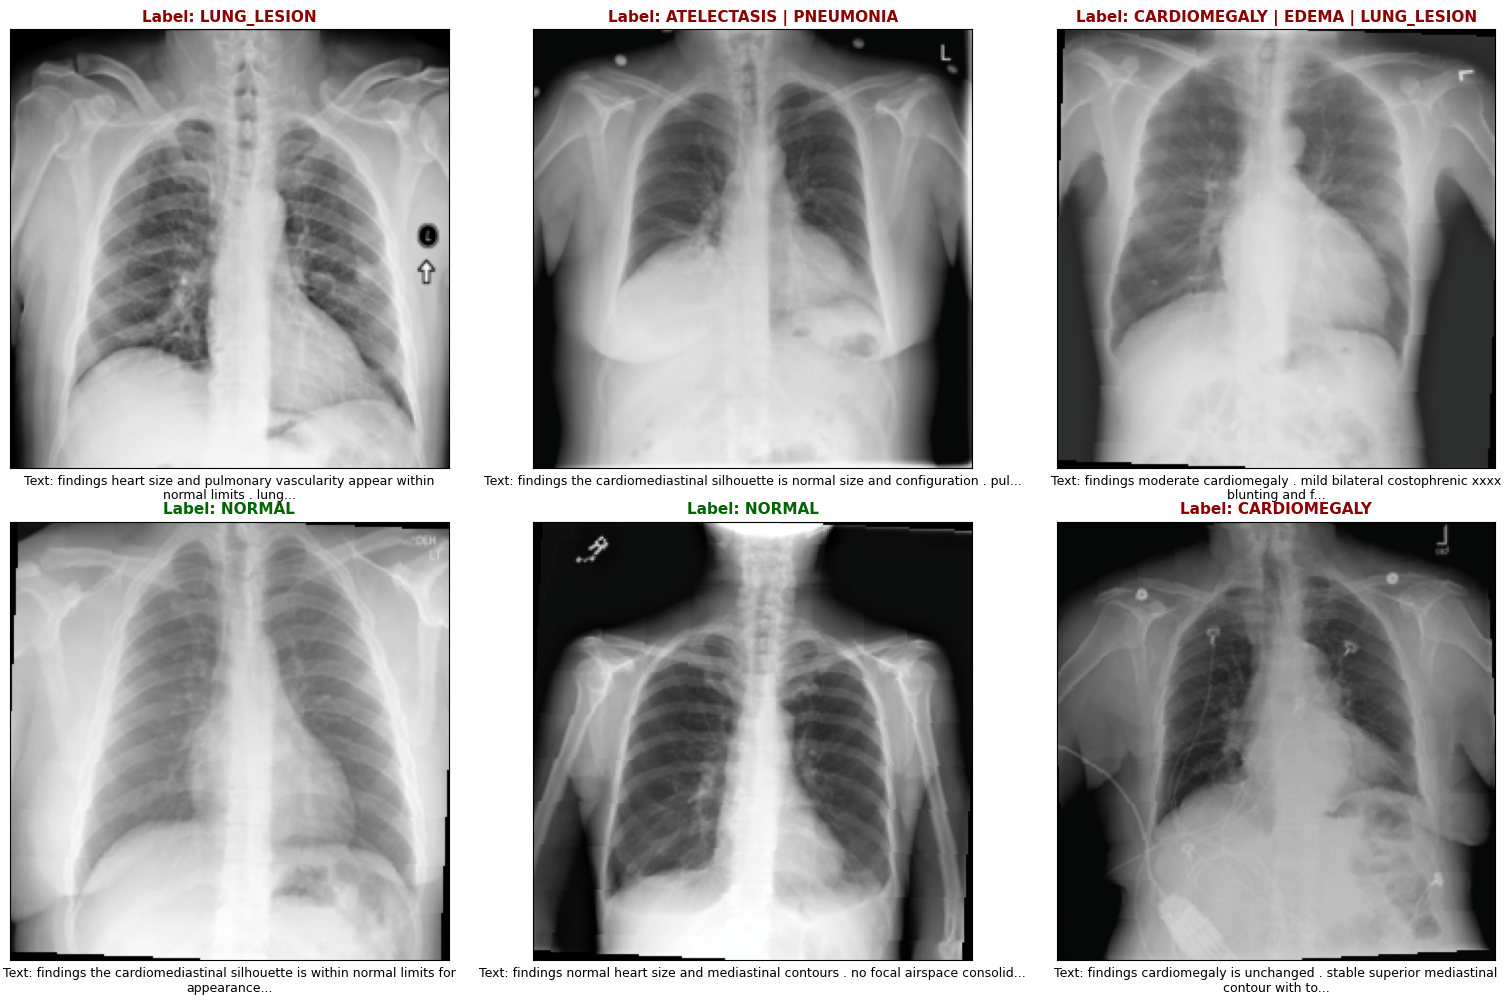

✓ Visual check complete. These samples are exactly what the CNN and Transformer will 'see'.


In [3]:
# ==============================================================================
# CELL 2.5: VISUAL SANITY CHECK FOR UNIVERSITY REPORT
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

print("Fetching a single batch from the training dataloader...")
# Get one batch of images, tokenized captions, and binary labels
images, captions, labels = next(iter(train_loader))

# Setup the plot (2 rows, 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i in range(6): # Display 6 samples
    # 1. Un-normalize the image tensor for plotting
    img = images[i].numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1) # Ensure pixel values are within [0, 1]
    
    # 2. Decode the caption (Convert integers back to words)
    cap_indices = captions[i].numpy()
    decoded_words = []
    for idx in cap_indices:
        # Ignore padding, start-of-sequence, and end-of-sequence tokens
        if idx not in [vocab.stoi["<PAD>"], vocab.stoi["<SOS>"], vocab.stoi["<EOS>"]]:
            decoded_words.append(vocab.itos.get(idx, "<UNK>"))
    full_caption = ' '.join(decoded_words)
    
    # Truncate caption if it's too long for the plot aesthetics
    display_caption = full_caption[:80] + "..." if len(full_caption) > 80 else full_caption
    
    # 3. Decode the actual disease labels
    actual_labels = mlb.inverse_transform(labels[i:i+1].numpy())[0]
    label_title = "NORMAL" if len(actual_labels) == 0 else " | ".join(actual_labels).upper()

    # 4. Plot
    axes[i].imshow(img)
    axes[i].set_title(f"Label: {label_title}", fontsize=11, fontweight='bold', color='darkred' if label_title != 'NORMAL' else 'darkgreen')
    axes[i].set_xlabel(f"Text: {display_caption}", fontsize=9, wrap=True)
    axes[i].set_xticks([])
    axes[i].set_yticks([])

plt.tight_layout()
plt.show()
print("✓ Visual check complete. These samples are exactly what the CNN and Transformer will 'see'.")